# Pill crop

Find the pill in each raw image with rotation-aware template matching and cut it out horizontally.

- Template: `data/pill_template.bmp` (a good pill, horizontal, cut tight, full-res).
- Matching on grayscale with `TM_CCOEFF_NORMED` (insensitive to brightness/contrast, so pill color doesn't matter much).
- The image is rotated, not the template, so the template never gets empty corners.
- Coarse-to-fine: 1/16 scale over 0-180 deg in 5 deg steps (the pill is 180 deg symmetric), then 1/4 scale +-4 deg in 1 deg steps inside a window around the coarse hit.
- Plain CPU: on these small images the CUDA build was not faster (per-call overhead ~6 ms beats the work), see the timing below.
- Final cut is a single full-res warp around the matched center, same size as the template.

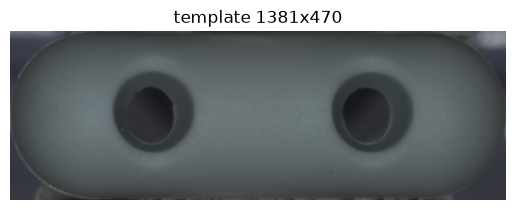

In [1]:
import glob, os
import cv2
import numpy as np
import matplotlib.pyplot as plt

DATA = 'data'
RAW = f'{DATA}/raw'    # raw/good, raw/defect
OUT = f'{DATA}/crops'  # same split names
TPL_PATH = f'{DATA}/pill_template.bmp'
COARSE = (1 / 16, np.arange(0, 180, 5))  # (scale, angles)
FINE_SCALE, FINE_SPAN = 0.25, 4          # refine +-FINE_SPAN deg, 1 deg step

tpl = cv2.imread(TPL_PATH)
assert tpl is not None, TPL_PATH
TH, TW = tpl.shape[:2]
plt.imshow(tpl[..., ::-1]); plt.title(f'template {TW}x{TH}'); plt.axis('off');

In [2]:
def gray(bgr, scale):
    return cv2.cvtColor(cv2.resize(bgr, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY)


def rotate_canvas(img, angle):
    """Rotate around the center on a canvas big enough to keep every pixel. Returns image and 2x3 matrix."""
    h, w = img.shape[:2]
    R = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1)
    cos, sin = abs(R[0, 0]), abs(R[0, 1])
    nw, nh = int(w * cos + h * sin), int(w * sin + h * cos)
    R[:, 2] += (nw / 2 - w / 2, nh / 2 - h / 2)
    return cv2.warpAffine(img, R, (nw, nh), borderMode=cv2.BORDER_REPLICATE), R


def search(img_g, tpl_g, angles):
    """Best (score, angle, center in img_g coords) over the given angles."""
    th, tw = tpl_g.shape
    best = (-1, 0, (0, 0))
    for a in angles:
        r, R = rotate_canvas(img_g, a)
        _, score, _, (x, y) = cv2.minMaxLoc(cv2.matchTemplate(r, tpl_g, cv2.TM_CCOEFF_NORMED))
        if score > best[0]:
            cx, cy = cv2.invertAffineTransform(R) @ (x + tw / 2, y + th / 2, 1)
            best = (score, a, (cx, cy))
    return best


def find_pill(img):
    """Return (center in full-res px, angle deg, score)."""
    s, angles = COARSE
    _, a, (cx, cy) = search(gray(img, s), gray(tpl, s), angles)
    # refine only in a window around the coarse hit: 5x faster than the whole image
    k = FINE_SCALE / s
    cx, cy = cx * k, cy * k
    t = gray(tpl, FINE_SCALE)
    r = int(max(t.shape) * 0.75)  # half window: the template at any angle plus coarse error
    g = gray(img, FINE_SCALE)
    x0, y0 = max(int(cx) - r, 0), max(int(cy) - r, 0)
    score, a, (wx, wy) = search(g[y0:int(cy) + r, x0:int(cx) + r], t, np.arange(a - FINE_SPAN, a + FINE_SPAN + 1, 1))
    return ((wx + x0) / FINE_SCALE, (wy + y0) / FINE_SCALE), a, score


def crop_pill(img):
    (cx, cy), a, score = find_pill(img)
    R = cv2.getRotationMatrix2D((cx, cy), a, 1)
    R[:, 2] += (TW / 2 - cx, TH / 2 - cy)  # matched center -> crop center
    return cv2.warpAffine(img, R, (TW, TH), borderMode=cv2.BORDER_REPLICATE), (cx, cy), a, score

## `rotate_canvas` step by step

On `good/11` (pill at ~48 deg) at 1/8 scale:
1. input, center marked
2. plain rotation into the same w x h frame: the corners fall outside and are lost
3. where the 4 corners land after rotation, and the bounding box `nw x nh` that holds them
4. same rotation + shift `(nw/2 - w/2, nh/2 - h/2)` into an `nw x nh` canvas, empty area black
5. same with `BORDER_REPLICATE` (what the code uses): no fake black edges for the matcher
6. template matched on the rotated canvas, and its center mapped back to the input with `invertAffineTransform(R)`

## One image

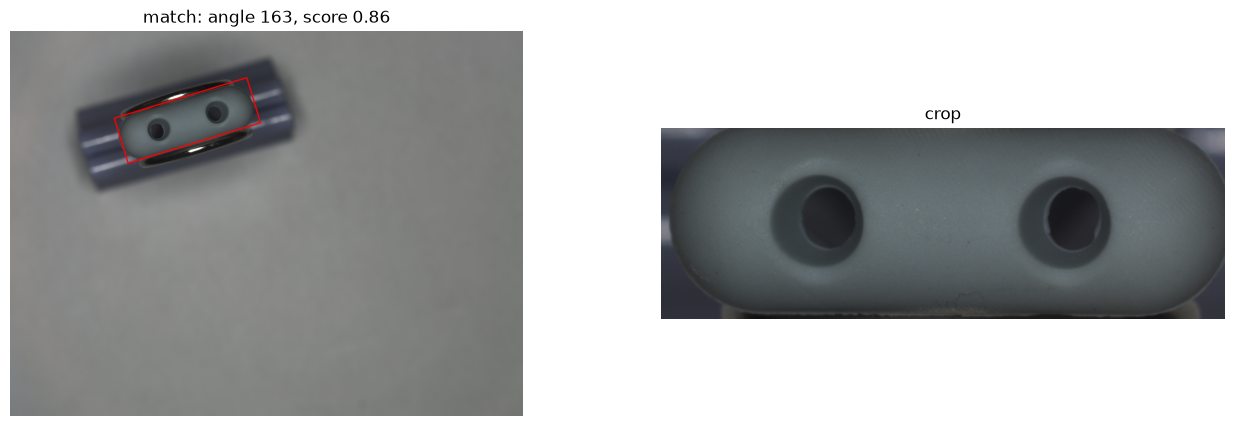

In [3]:
img = cv2.imread(f'{RAW}/good/8.bmp')
crop, (cx, cy), a, score = crop_pill(img)
box = cv2.boxPoints(((float(cx), float(cy)), (TW, TH), float(a))).astype(np.int32)
vis = cv2.polylines(img.copy(), [box], True, (0, 0, 255), 12)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].imshow(vis[..., ::-1]); ax[0].set_title(f'match: angle {a:.0f}, score {score:.2f}')
ax[1].imshow(crop[..., ::-1]); ax[1].set_title('crop')
for x in ax: x.axis('off')

## Crop all images

In [4]:
import time
crops = {}
for split in ('good', 'defect'):
    os.makedirs(f'{OUT}/{split}', exist_ok=True)
    for f in sorted(glob.glob(f'{RAW}/{split}/*.bmp'), key=lambda p: int(os.path.basename(p)[:-4])):
        img = cv2.imread(f)
        t0 = time.perf_counter()
        c, _, a, score = crop_pill(img)
        ms = (time.perf_counter() - t0) * 1000
        name = os.path.basename(f)[:-4]
        cv2.imwrite(f'{OUT}/{split}/{name}.png', c)
        crops[f'{split}/{name}'] = (c, score)
        print(f"{split}/{name}: score {score:.2f}, angle {a:.0f}, {ms:.0f} ms")
print(len(crops), 'crops saved to', OUT)

good/1: score 0.83, angle 159, 128 ms


good/2: score 0.89, angle 165, 131 ms


good/3: score 0.89, angle 169, 126 ms


good/4: score 0.90, angle 168, 128 ms
good/5: score 0.86, angle 168, 126 ms


good/6: score 0.85, angle 159, 126 ms
good/7: score 0.84, angle 164, 128 ms


good/8: score 0.86, angle 163, 126 ms


... (11 outputs left out)

defect/10: score 0.85, angle 162, 133 ms


defect/11: score 0.61, angle 159, 135 ms


defect/12: score 0.52, angle 155, 134 ms


defect/13: score 0.72, angle 110, 133 ms
defect/14: score 0.66, angle 173, 129 ms
26 crops saved to data/crops


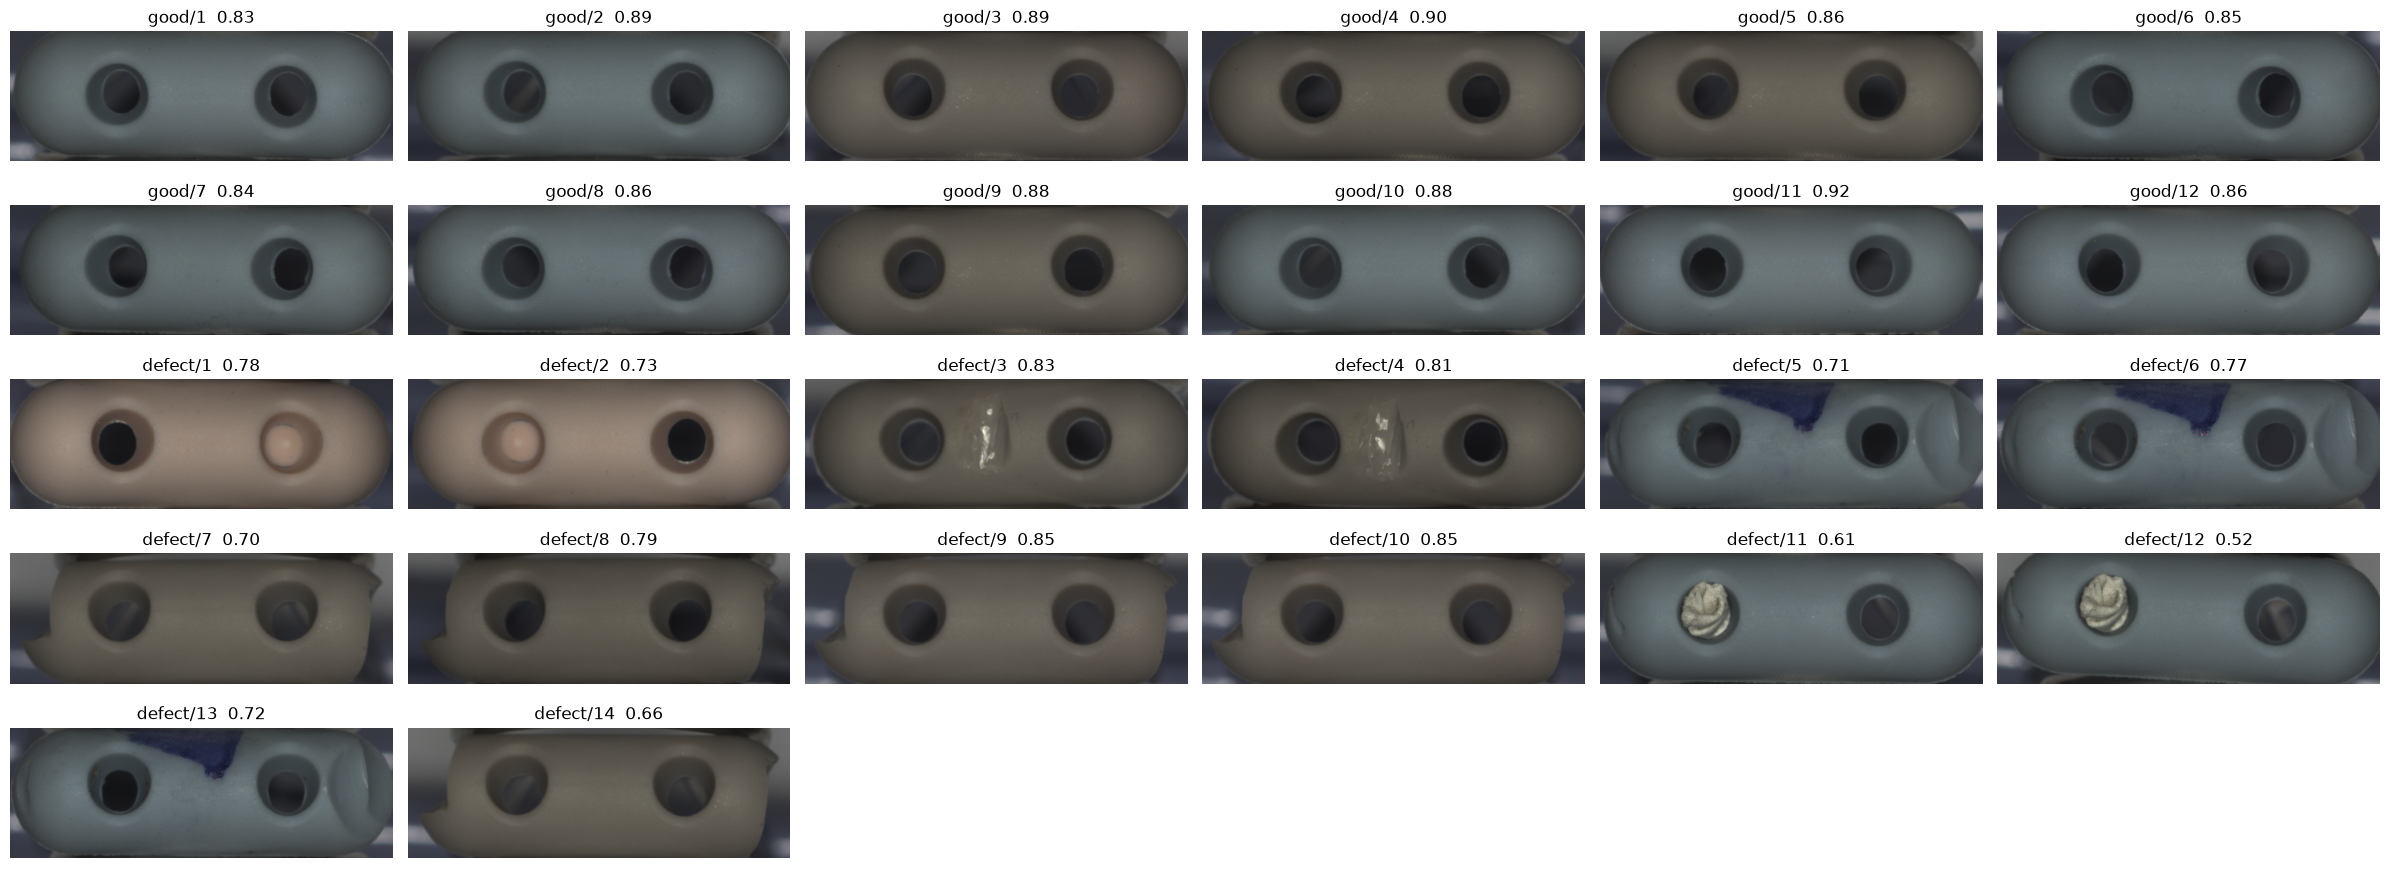

In [5]:
cols = 6
rows = -(-len(crops) // cols)
fig, ax = plt.subplots(rows, cols, figsize=(cols * 4, rows * 1.8))
for x in ax.flat:
    x.axis('off')
for x, (k, (c, score)) in zip(ax.flat, crops.items()):
    x.imshow(c[..., ::-1]); x.set_title(f'{k}  {score:.2f}')
plt.tight_layout()